# YOLO26: Rock, Paper, Scissors object detection

    **Learning outcomes:** distinguish classification and detection, inspect bounding-box
    labels, fine-tune YOLO26, evaluate held-out images, and display English predictions.

    This English edition uses Ultralytics YOLO26 instead of the original external
    PaddleYOLO workflow. Use the small `yolo26n.pt` model for the classroom. A pretrained
    COCO model does not know the three hand-gesture classes until it is fine-tuned.

    Prepare a **bounding-box detection** export, not a folder-only classification dataset.
    Run `02-object-detection\.venv\Scripts\python.exe scripts\fetch_rps.py` from the
    `english` directory, as the module README describes, to build the English Rock Paper
    Scissors dataset this notebook trains on.

In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "Select the Python 3.12 project kernel."
assert version('torch').split("+")[0] == '2.14.1', "Select the locked project environment."
print("Python:", sys.version.split()[0])
print('torch' + ":", version('torch'))
print("Run mode:", 'Default classroom training parameters')

Python: 3.12.15
torch: 2.14.1
Run mode: Default classroom training parameters


In [2]:
from pathlib import Path
import os
import sys

# Find the English course root without relying on a specific working directory.
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "COURSE_ROOT").is_file()), None)
if COURSE is None and (start / "english" / "COURSE_ROOT").is_file():
    COURSE = start / "english"
if COURSE is None:
    raise RuntimeError("Start Jupyter inside the project or the english directory.")
sys.path.insert(0, str(COURSE / "common"))
os.environ.setdefault("HF_HOME", str(COURSE / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(COURSE / "data" / "torch-cache"))

'E:\\deep-learning-lab\\english\\data\\torch-cache'

In [3]:
import json
MODULE = COURSE / "02-object-detection"
OUTPUT = MODULE / "outputs"
# Keep Ultralytics settings local to this edition, before importing the package.
os.environ["YOLO_CONFIG_DIR"] = str(OUTPUT / "ultralytics-config")
import torch
from ultralytics import YOLO, settings
import ultralytics
from ultralytics.utils import set_logging
import matplotlib.pyplot as plt
from detection_data import prepare_rps

OUTPUT.mkdir(parents=True, exist_ok=True)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
settings.update({"datasets_dir": str(MODULE / "data"),
                 "weights_dir": str(OUTPUT / "weights"),
                 "runs_dir": str(OUTPUT / "runs")})
# Ultralytics redraws a per-iteration progress bar; inside a saved notebook every redraw
# becomes a stored output record, so raise its log level and read the curve from results.png.
set_logging(verbose=False)
torch.set_num_threads(2)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Ultralytics version:", ultralytics.__version__)
print("Device:", DEVICE)

Ultralytics version: 8.4.177
Device: cpu


## 1. Validate the dataset and label mapping

    Each annotation row contains `class_id x_center y_center width height`. Coordinates
    are normalized by image width and height. Class IDs must agree with `data.yaml`.
    We lowercase English names but preserve their ID order. Training, validation, and
    test splits must be separate; the validator rejects identical images across splits.

    `COURSE_SMOKE=1` explicitly switches to COCO8 to test the YOLO26 software pipeline.
    That diagnostic run is not a Rock Paper Scissors experiment or its evaluation.

In [4]:
if SMOKE:
    from detection_data import prepare_coco8
    DATA_CONFIG = str(prepare_coco8(MODULE / "data", OUTPUT / "coco8-smoke.yaml"))
    print("SMOKE TEST ONLY: COCO8 pipeline check; not hand-gesture training.")
else:
    DATA_CONFIG = OUTPUT / "rps-data.yaml"
    config, counts = prepare_rps(MODULE / "data" / "rock-paper-scissors", DATA_CONFIG)
    print("English class mapping:", dict(enumerate(config["names"])))
    print("Validated split sizes:", counts)
    DATA_CONFIG = str(DATA_CONFIG)

English class mapping: {0: 'rock', 1: 'paper', 2: 'scissors'}
Validated split sizes: {'train': {'images': 1485, 'boxes': 1973}, 'val': {'images': 50, 'boxes': 80}, 'test': {'images': 50, 'boxes': 80}}


## 2. Load pretrained weights and fine-tune

    YOLO26 supports training, validation, prediction, and export through the Ultralytics
    Python API. It also supports an end-to-end inference path. IoU, precision, recall,
    and mAP remain important; do not assume all historical YOLO post-processing details
    apply unchanged. See the linked official model guide for version-specific behavior.

    `workers=0` avoids notebook multiprocessing problems on Windows. The initial download
    needs internet. The smoke run uses a smaller image size and one epoch for speed. The
    classroom image size is 320 rather than 640 because one 640-pixel epoch measured over
    twenty minutes on this CPU, while a 320-pixel epoch measured about 205 seconds. The cell
    ends by displaying `results.png` from the run folder, so loss and mAP are visible inline.

Epochs: 10; image size: 320; smoke: False

Saved checkpoint: best.pt


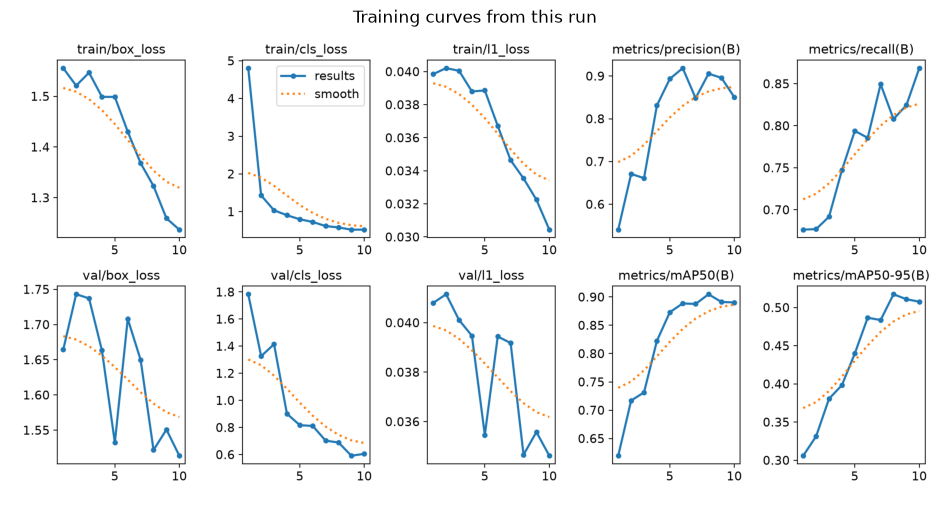

In [5]:
weights = OUTPUT / "weights" / "yolo26n.pt"
weights.parent.mkdir(parents=True, exist_ok=True)
model = YOLO(str(weights))
# Measured on this classroom CPU with two torch threads: one 320-pixel epoch takes about
# 205 seconds, while a 640-pixel epoch takes more than twenty minutes. The defaults below
# therefore keep a full run near thirty minutes. On a GPU, raise EPOCHS and IMGSZ.
# COURSE_EPOCHS shortens a pipeline check; the classroom default stays at ten epochs.
EPOCHS = int(os.environ.get("COURSE_EPOCHS", 1 if SMOKE else 10))
IMGSZ = 64 if SMOKE else 320
print(f"Epochs: {EPOCHS}; image size: {IMGSZ}; smoke: {SMOKE}")
# verbose=False keeps the saved notebook readable: the per-iteration progress bar added
# about two thousand output records to the training cell without adding teaching value.
results = model.train(data=DATA_CONFIG, epochs=EPOCHS, imgsz=IMGSZ,
                      batch=2 if SMOKE else 8, workers=0, device=DEVICE,
                      seed=42, deterministic=True, verbose=False,
                      project=str(OUTPUT / "runs"),
                      name="coco8-smoke" if SMOKE else "rps-yolo26n",
                      exist_ok=False, plots=True, cache=False)
best = Path(model.trainer.best)
if not best.exists():
    raise RuntimeError("Training did not produce a best checkpoint.")
print("Saved checkpoint:", best.name)

# Show the curves this run wrote into its own folder before reading the metrics table.
curves = Path(model.trainer.save_dir) / "results.png"
if curves.exists():
    figure, axis = plt.subplots(figsize=(12, 8))
    axis.imshow(plt.imread(curves))
    axis.axis("off")
    axis.set_title("Training curves from this run")
    plt.show()
else:
    print("Expected plot not found:", curves)


## 3. Validate the trained checkpoint

    Select model settings with validation data. Use the independent test split only after
    those decisions. COCO8 smoke mode has no separate test experiment, so it reports
    validation diagnostics only. mAP50 and mAP50-95 use different IoU criteria.

test mAP50: 0.9045
test mAP50-95: 0.5236


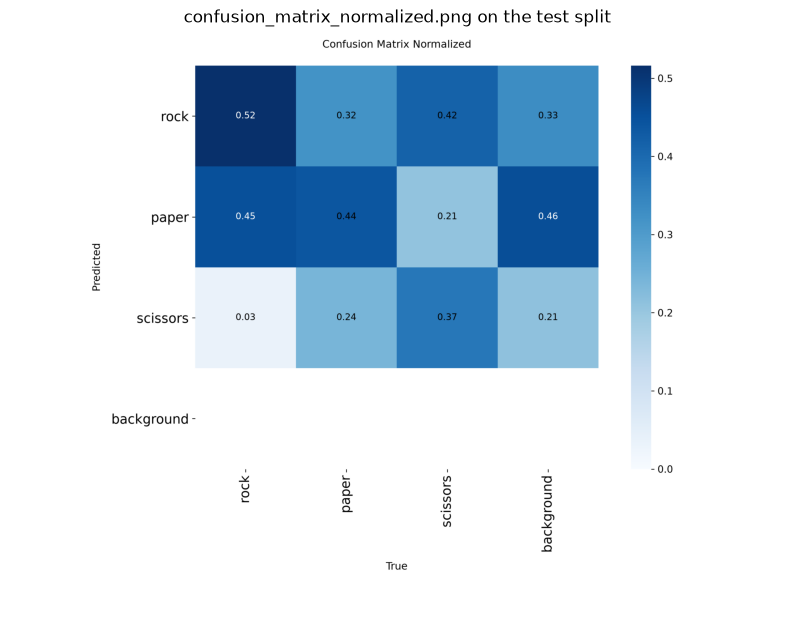

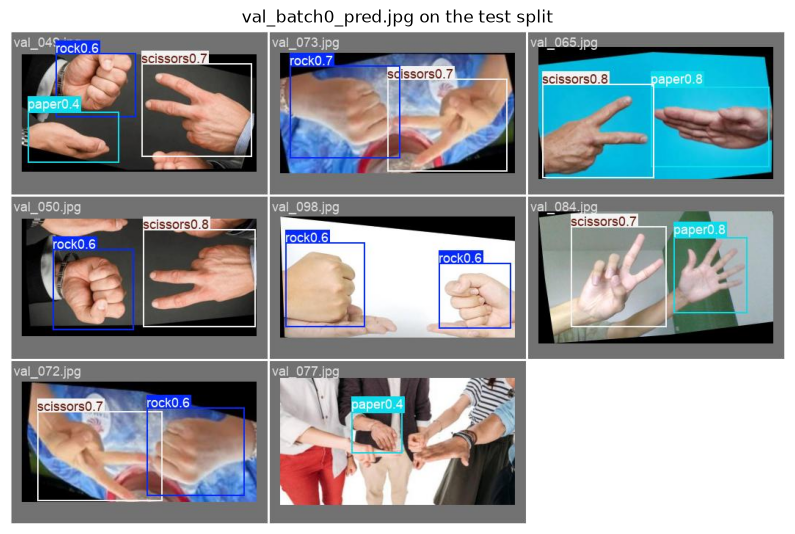

In [6]:
trained = YOLO(str(best))
split = "val" if SMOKE else "test"
metrics = trained.val(data=DATA_CONFIG, split=split, device=DEVICE,
                      imgsz=IMGSZ, workers=0, batch=2 if SMOKE else 8,
                      project=str(OUTPUT / "runs"), name="evaluation")
print(f"{split} mAP50: {metrics.box.map50:.4f}")
print(f"{split} mAP50-95: {metrics.box.map:.4f}")
report = {"smoke_test": SMOKE, "evaluation_split": split,
          "dataset": "COCO8" if SMOKE else "Rock Paper Scissors",
          "map50": float(metrics.box.map50), "map50_95": float(metrics.box.map),
          "ultralytics_version": ultralytics.__version__}
(OUTPUT / ("smoke-metrics.json" if SMOKE else "rps-metrics.json")).write_text(
    json.dumps(report, indent=2), encoding="utf-8")

# The evaluation folder explains those numbers: a normalized confusion matrix and validation
# crops with the predicted boxes drawn.
for name in ("confusion_matrix_normalized.png", "val_batch0_pred.jpg"):
    figure_path = Path(metrics.save_dir) / name
    if figure_path.exists():
        figure, axis = plt.subplots(figsize=(10, 10))
        axis.imshow(plt.imread(figure_path))
        axis.axis("off")
        axis.set_title(f"{name} on the {split} split")
        plt.show()
    else:
        print("Expected plot not found:", figure_path)

## 4. Draw predictions with English labels

Class: paper; confidence: 0.708


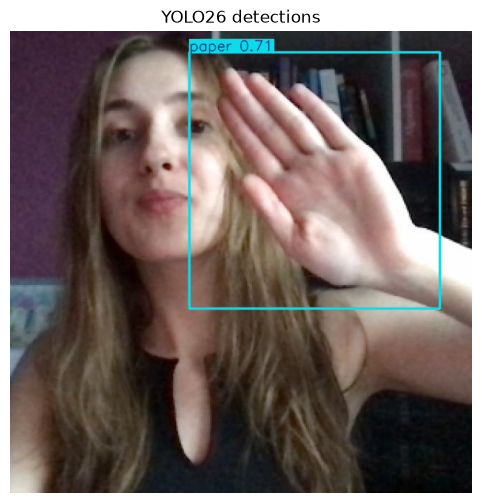

In [7]:
if SMOKE:
    from ultralytics.utils import ASSETS
    sample = ASSETS / "bus.jpg"
else:
    directory = MODULE / "data" / "rock-paper-scissors" / "test" / "images"
    sample = next(p for p in directory.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
prediction = trained.predict(source=str(sample), conf=0.25, device=DEVICE,
                              imgsz=IMGSZ, verbose=False)[0]
for box in prediction.boxes:
    print(f"Class: {prediction.names[int(box.cls.item())]}; confidence: {float(box.conf.item()):.3f}")
plt.figure(figsize=(8, 6))
plt.imshow(prediction.plot()[:, :, ::-1])
plt.title("YOLO26 detections" if not SMOKE else "COCO8 diagnostic predictions")
plt.axis("off")
plt.show()

## Exercises and optional export

    Inspect missed objects and false positives. Compare two confidence thresholds without
    retraining. Compare nano and small models using the same splits. Inspect the exported
    dataset for near-duplicate photos or the same participant appearing across splits;
    exact-byte duplicate checks alone cannot detect all leakage.

    Export is optional: `trained.export(format="onnx")`. It may install additional export
    dependencies; first verify numerical agreement with the original model.

    Sources: [YOLO26](https://docs.ultralytics.com/models/yolo26/),
    [training API](https://docs.ultralytics.com/modes/train/),
    [Rock Paper Scissors detection dataset](https://universe.roboflow.com/roboflow-58fyf/rock-paper-scissors-sxsw)
    through its [CC BY 4.0 mirror](https://huggingface.co/datasets/Xuban/rock-paper-scissors-roboflow).